# Project 1: Data visualization

| Column | What it measures | Units in the original |
|:--|:--|:--|
| `sex` | M (male), F (female), or I (infant), meaning too young to tell | category |
| `length` | The longest dimension of the shell | mm |
| `diameter` | The shell's width, measured perpendicular to the length | mm |
| `height` | The shell's thickness, measured with the meat still inside | mm |
| `whole_weight` | The whole animal: meat, gut and shell | grams |
| `shucked_weight` | The meat only, after it is taken out of the shell | grams |
| `viscera_weight` | The gut, weighed after bleeding | grams |
| `shell_weight` | The shell, weighed after being dried | grams |
| `rings` (target) | The number of growth rings in the shell, counted under a microscope | count. Age in years ≈ rings + 1.5 |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

df = pl.read_csv("./data/abalone.csv.zst")
FEATURES = [c for c in df.columns if c not in ("sex", "rings")]
print(df.shape)
df.head()

(4177, 9)


sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
str,f64,f64,f64,f64,f64,f64,f64,i64
"""M""",0.455,0.365,0.095,0.514,0.2245,0.101,0.15,15
"""M""",0.35,0.265,0.09,0.2255,0.0995,0.0485,0.07,7
"""F""",0.53,0.42,0.135,0.677,0.2565,0.1415,0.21,9
"""M""",0.44,0.365,0.125,0.516,0.2155,0.114,0.155,10
"""I""",0.33,0.255,0.08,0.205,0.0895,0.0395,0.055,7


We have one categorical feature: `sex` and all the other 7 features are numerical and our target `rings` is numerical too

## 1.1 Distribution of every feature

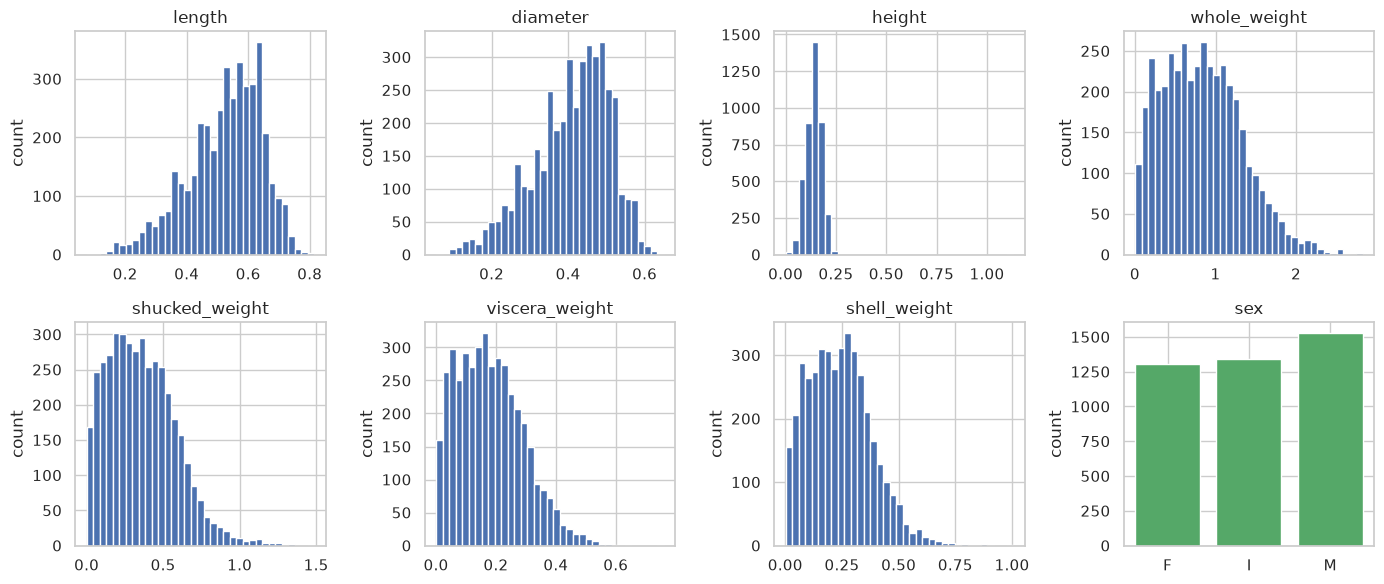

In [2]:
from pathlib import Path

Path("figures").mkdir(exist_ok=True)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.ravel(), FEATURES):
    ax.hist(df[c].to_numpy(), bins=35, edgecolor="white")
    ax.set(title=c, xlabel="", ylabel="count")
counts = df.group_by("sex").len().sort("sex")
axes.ravel()[-1].bar(counts["sex"].to_list(), counts["len"].to_list(), color="C2")
axes.ravel()[-1].set(title="sex", ylabel="count")
fig.tight_layout()
fig.savefig("figures/distributions.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** the 7 numeric features are positive and have different scales (`length` and `diameter` around 0.1 to 0.8, the weights up to about 2.8). The weights are right-skewed, `length` and `diameter` are left-skewed (a tail of small animals), and `height` is squeezed because of an outlier. `sex` seems balanced (F 1307, I 1342, M 1528).

**Decision:** we will need to standardize the features for the learners that use distances or gradients maybe encode `sex`.

## 1.2 Boxplot of every feature

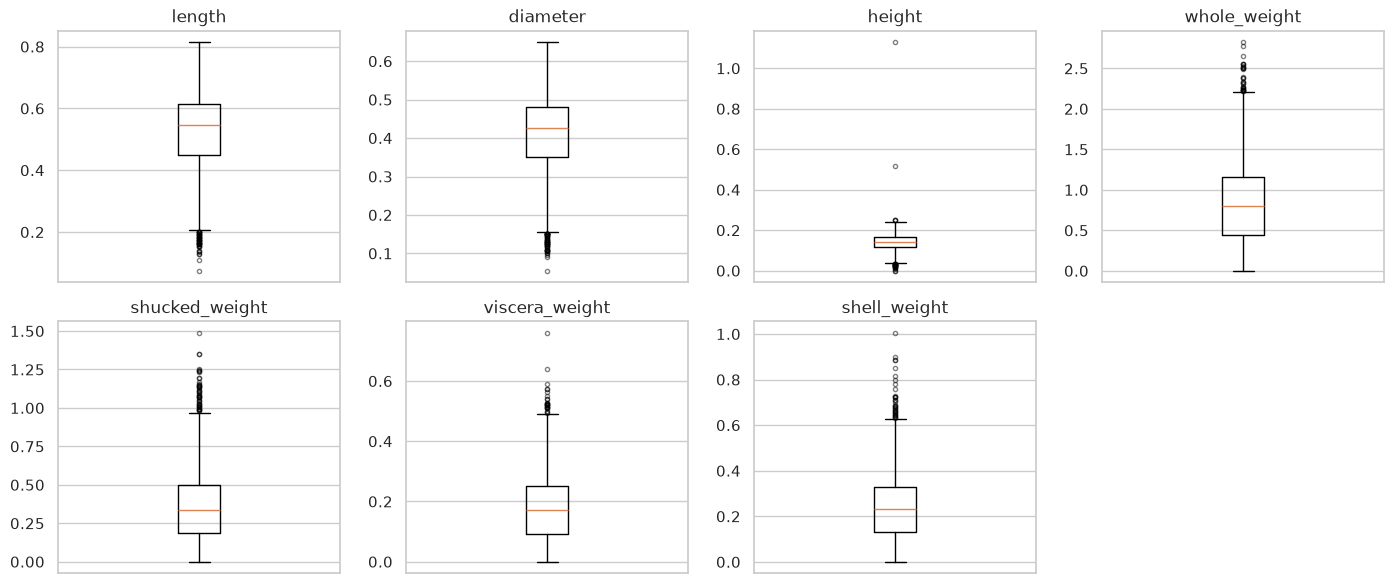

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.ravel(), FEATURES):
    ax.boxplot(df[c].to_numpy(), orientation="vertical", flierprops={"markersize": 3, "alpha": 0.5})
    ax.set(title=c, xticks=[])
axes.ravel()[-1].axis("off")
fig.tight_layout()
plt.show()

**Finding:** `height` has two points far from the rest (about 0.52 and 1.13) and two impossible zeros. The outliers of `length` and `diameter` are all on the low side (small, young animals), and those of the four weights are all on the high side (the right skew), so it seems they are real animals.

**Decision:** remove the two outliers and remove the two zeros. As tehy are only four values that could greatly influence the scale I will remove them in the preprocessing.

## 1.3 `height` without the 2 extreme values

removed: [0.515 1.13 ]  remaining: 4175


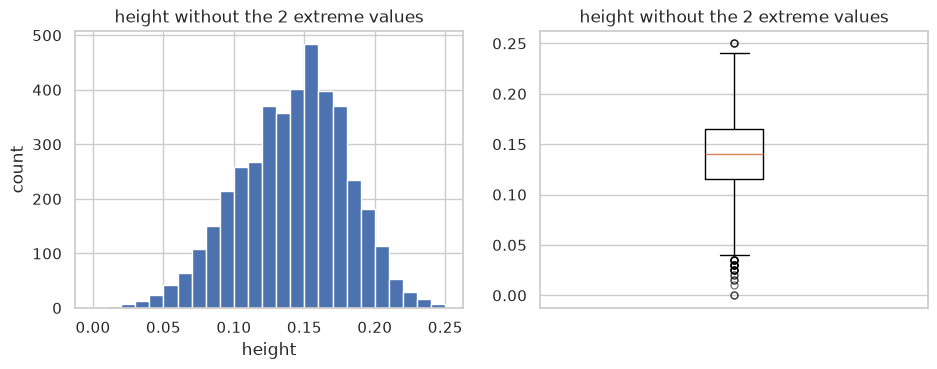

In [4]:
height = df["height"].to_numpy()
keep = height < 0.3
print("removed:", height[~keep], " remaining:", keep.sum())
h = height[keep]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(h, bins=25, edgecolor="white")
ax[0].set(title="height without the 2 extreme values", xlabel="height", ylabel="count")
ax[1].boxplot(h, orientation="vertical", flierprops={"markersize": 5, "alpha": 0.5})
ax[1].set(title="height without the 2 extreme values", xticks=[])
plt.show()

**Finding:** without the two extreme values (0.515 and 1.13), `height` is roughly symmetric between 0.02 and 0.25.

**Decision:** exclude these two rows as data errors as said before. The pairplot and the correlation matrix below are computed without the two extreme rows.

## 1.4 The target: `rings`

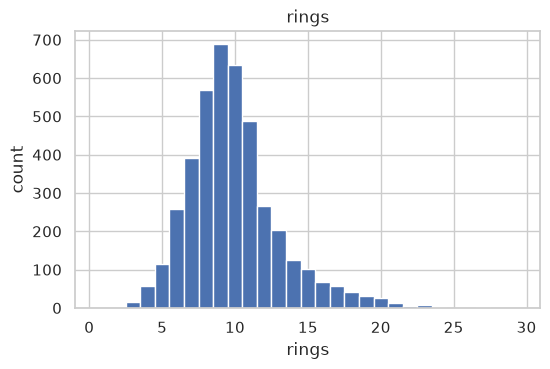

mean 9.93  std 3.22  median 9  min 1  max 29
skew: 1.11


In [5]:
rings = df["rings"].to_numpy()
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.hist(rings, bins=np.arange(rings.min() - 0.5, rings.max() + 1.5, 1), edgecolor="white")
ax.set(title="rings", xlabel="rings", ylabel="count")
fig.savefig("figures/target.png", dpi=150, bbox_inches="tight")
plt.show()
print("mean %.2f  std %.2f  median %.0f  min %d  max %d" % (rings.mean(), rings.std(), np.median(rings), rings.min(), rings.max()))
print("skew: %.2f" % stats.skew(rings))

**Finding:** `rings` is an integer from 1 to 29, centred around 9 to 10 (mean 9.93, median 9, std 3.22) with a right tail (skew 1.11).

**Decision:** report RMSE as the main metric and MAE as a second one, because the tail makes RMSE sensitive to a few old animals(the long tail in the right).

## 1.5 Pairplot: features against each other and against the target

rows plotted: 4175 of 4177


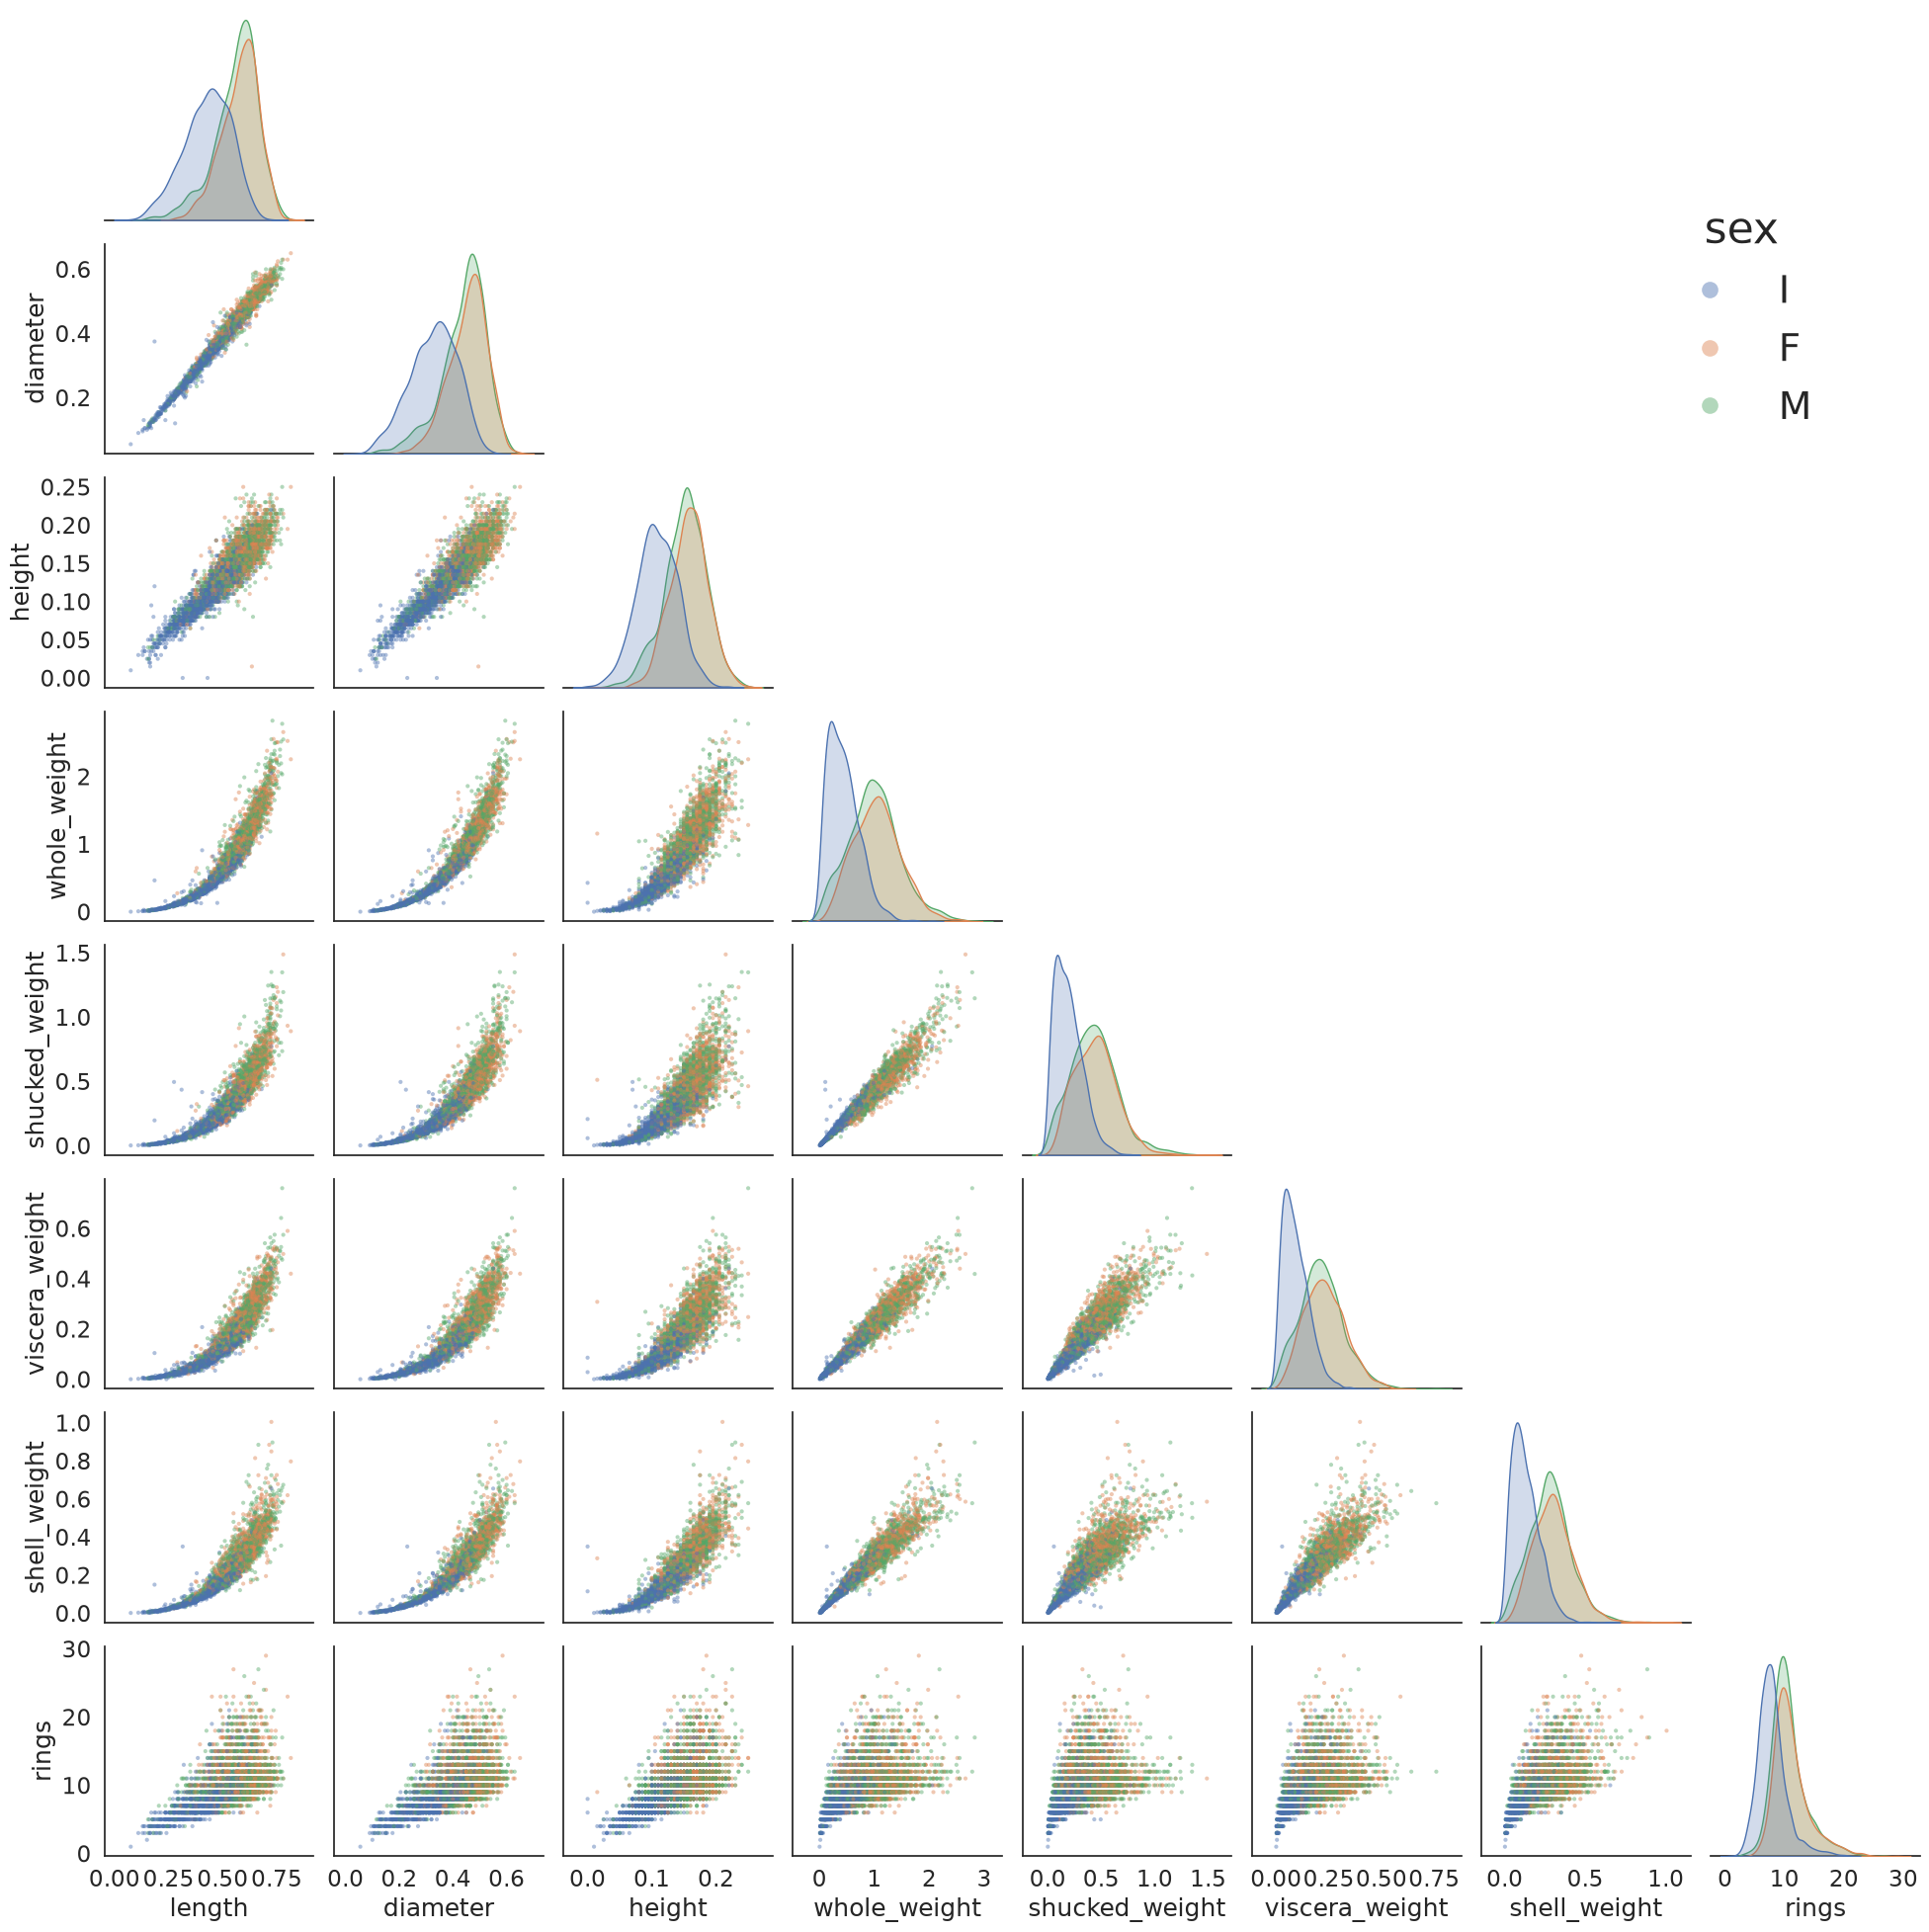

In [6]:
df_pair = df.filter(pl.col("height") < 0.3).select(FEATURES + ["rings", "sex"])
print("rows plotted:", df_pair.height, "of", df.height)

with sns.axes_style("white"), sns.plotting_context("notebook", font_scale=1.5):
    g = sns.pairplot(
        df_pair.to_pandas(),
        hue="sex", hue_order=["I", "F", "M"],
        corner=True,
        plot_kws={"s": 9, "alpha": 0.45, "edgecolor": "none"},
    )
sns.move_legend(g, "upper right", bbox_to_anchor=(0.9, 0.9), title="sex",
                fontsize=28, title_fontsize=32, markerscale=4)
g.savefig("figures/pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** infants (`I`) separate clearly: they are smaller, lighter and have fewer rings, while females and males overlap almost completely. The size and weight features move together (near-linear for `length` and `diameter`, curved against the weights because weight grows with volume). But we can see a lot of heterocedascity as we grow in every feature.

**Decision:** Since the spread grows with size, we're expecting larger errors for big and old animals.

## 1.6 Pearson correlation

rows used: 4175 of 4177


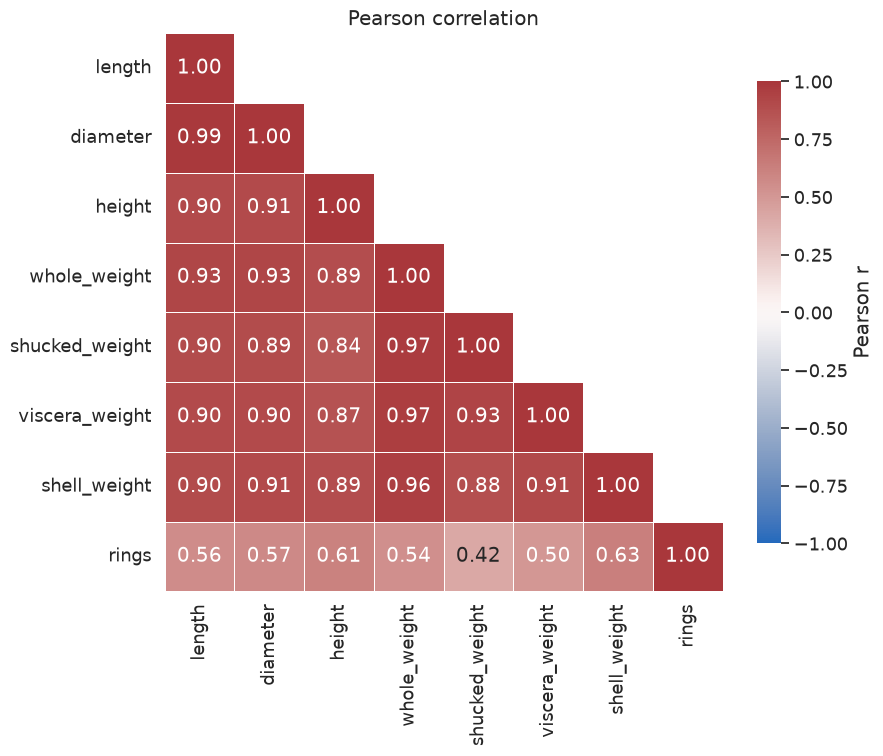

shell_weight      0.628
height            0.610
diameter          0.575
length            0.557
whole_weight      0.541
viscera_weight    0.504
shucked_weight    0.421
Name: rings, dtype: float64


In [7]:
df_corr = df.filter(pl.col("height") < 0.3).select(FEATURES + ["rings"])
print("rows used:", df_corr.height, "of", df.height)
corr = df_corr.to_pandas().corr(method="pearson")

with sns.axes_style("white"), sns.plotting_context("notebook", font_scale=1.2):
    fig, ax = plt.subplots(figsize=(9, 7.5))
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f",
                cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
                cbar_kws={"shrink": 0.8, "label": "Pearson r"}, ax=ax)
    ax.set_title("Pearson correlation")
fig.savefig("figures/correlation.png", dpi=150, bbox_inches="tight")
plt.show()

print(corr["rings"].drop("rings").sort_values(ascending=False).round(3))

**Finding:** the size features are almost one variable (`length` and `diameter` r = 0.99) and the four weights correlate 0.88 to 0.97 with each other. Against `rings` the correlations are only moderate: `shell_weight` 0.63, `height` 0.61, `diameter` 0.57, `length` 0.56, `whole_weight` 0.54, `viscera_weight` 0.50, `shucked_weight` 0.42. No single feature predicts the age.

**Decision:** some features are strongly collinear, maybe regularization with  drop some features and have similar results.